In [60]:
import pandas as pd
import numpy as np

import scipy.stats as stats

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer

from sklearn.pipeline import Pipeline

In [36]:
df = pd.read_csv('E:\\Data Science\\Machine Learning\\data\\covid_toy.csv', usecols = ['age','gender', 'fever', 'has_covid'])

In [37]:
df.head()

,age,gender,fever,has_covid
0,60,Male,103.0,No
1,27,Male,100.0,Yes
2,42,Male,101.0,No
3,31,Female,98.0,No
4,65,Female,101.0,No


In [38]:
X,y = df.iloc[:, :3], df.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size= 0.3)

In [76]:
X_train.head()

,age,gender,fever
37,55,Male,100.0
66,51,Male,104.0
93,27,Male,100.0
70,68,Female,101.0
39,50,Female,103.0


#### Performance without functional transformation:

In [67]:
trf = ColumnTransformer([
    ('ohe', OneHotEncoder(sparse_output = False), [1]),
    ('impute_fever', SimpleImputer(), [2])
], remainder= 'passthrough')

In [68]:
X_train_transformed = trf.fit_transform(X_train)
X_test_transformed = trf.transform(X_test)

le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.fit_transform(y_test)

In [69]:
log_regn = LogisticRegression()
dtree = DecisionTreeClassifier()

log_regn.fit(X_train_transformed, y_train)
dtree.fit(X_test_transformed, y_test)

DecisionTreeClassifier()

In [70]:
y_pred = log_regn.predict(X_test_transformed)
y_pred2 = dtree.predict(X_test_transformed)

print(f"logistic regression: {accuracy_score(y_test, y_pred)}")
print(f'Decision Tree: {accuracy_score(y_test, y_pred2)}')

logistic regression: 0.6
Decision Tree: 1.0


#### Performance after applying transformation:

In [78]:
X_train.head()

,age,gender,fever
37,55,Male,100.0
66,51,Male,104.0
93,27,Male,100.0
70,68,Female,101.0
39,50,Female,103.0


In [79]:
trf1 = ColumnTransformer([
    ('impute_fever', SimpleImputer(), [2]),
    ('ohe', OneHotEncoder(sparse_output = False), [1])
], remainder= 'passthrough')

In [80]:
trf2 = ColumnTransformer([
    ('log', FunctionTransformer(func = np.log1p), [0,2])
], remainder= 'passthrough')

In [81]:
trf3 = LogisticRegression()

trf4 = DecisionTreeClassifier()

In [82]:
## creating pipeline to apply ohe, imputation and log transformation:

pipe_LR = Pipeline([
    ('trf1', trf1),
    ('trf2', trf2),
    ('trf3', trf3)
])

In [84]:
pipe_LR.fit(X_train, y_train)

Pipeline(steps=[('trf1',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('impute_fever',
                                                  SimpleImputer(), [2]),
                                                 ('ohe',
                                                  OneHotEncoder(sparse_output=False),
                                                  [1])])),
                ('trf2',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('log',
                                                  FunctionTransformer(func=<ufunc 'log1p'>),
                                                  [0, 2])])),
                ('trf3', LogisticRegression())])

In [85]:
pipe_DT = Pipeline([
    ('trf1', trf1),
    ('trf2', trf2),
    ('trf4', trf4)
])

In [86]:
pipe_DT.fit(X_train, y_train)

Pipeline(steps=[('trf1',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('impute_fever',
                                                  SimpleImputer(), [2]),
                                                 ('ohe',
                                                  OneHotEncoder(sparse_output=False),
                                                  [1])])),
                ('trf2',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('log',
                                                  FunctionTransformer(func=<ufunc 'log1p'>),
                                                  [0, 2])])),
                ('trf4', DecisionTreeClassifier())])

In [87]:
y_pred = pipe_LR.predict(X_test)
y_pred2 = pipe_DT.predict(X_test)

print(f"Logistic regression: {accuracy_score(y_pred, y_test)}")
print(f"decision tree: {accuracy_score(y_pred2, y_test)}")

Logistic regression: 0.6
decision tree: 0.5333333333333333


C:\Users\Anwoy\AppData\Local\Temp\ipykernel_9544\2806889466.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X['age'])


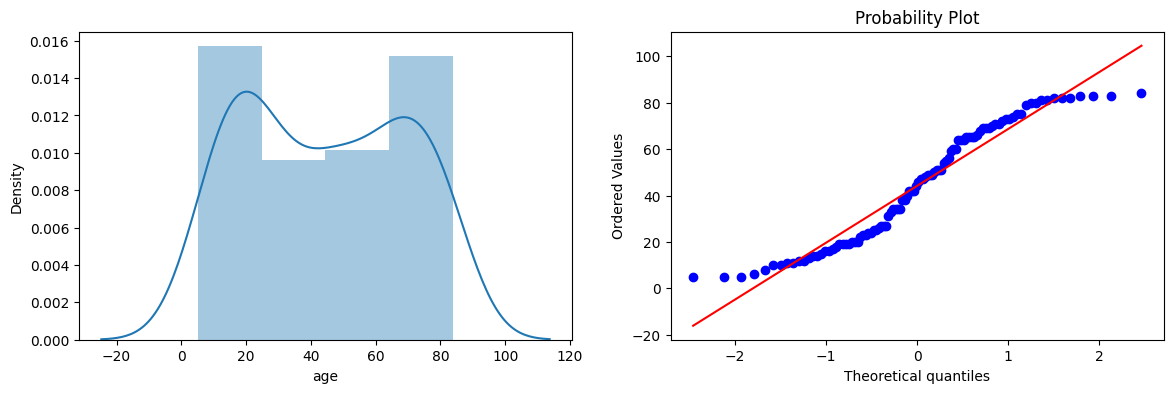

In [95]:
plt.figure(figsize= (14,4))
plt.subplot(121)
sns.distplot(X['age'])

plt.subplot(122)
stats.probplot(X['age'], dist= 'norm', plot = plt)
plt.show()

In [106]:
func_trans = FunctionTransformer(func = np.log1p)
X_transformed = func_trans.fit_transform(X[['age','fever']])

C:\Users\Anwoy\AppData\Local\Temp\ipykernel_9544\1179240597.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_transformed['age'])


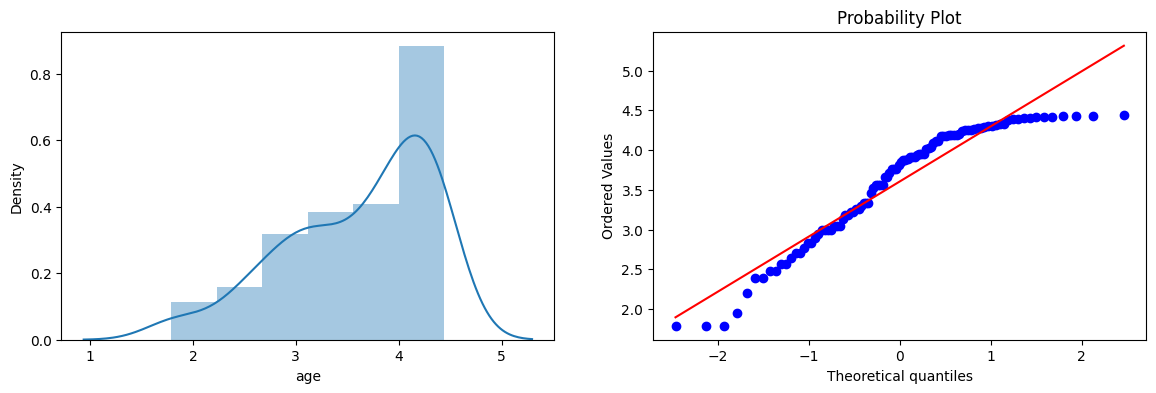

In [107]:
plt.figure(figsize= (14,4))
plt.subplot(121)
sns.distplot(X_transformed['age'])

plt.subplot(122)
stats.probplot(X_transformed['age'], dist= 'norm', plot = plt)
plt.show()